In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

columns = [
    "erythema", "scaling", "definite_borders", "itching",
    "koebner_phenomenon", "polygonal_papules", "follicular_papules",
    "oral_mucosal_involvement", "knee_and_elbow_involvement",
    "scalp_involvement", "family_history", "melanin_incontinence",
    "eosinophils_in_the_infiltrate", "PNL_infiltrate",
    "fibrosis_of_the_papillary_dermis", "exocytosis",
    "acanthosis", "hyperkeratosis", "parakeratosis",
    "clubbing_of_the_rete_ridges", "elongation_of_the_rete_ridges",
    "thinning_of_the_suprapapillary_epidermis",
    "spongiform_pustule", "munro_microabcess",
    "focal_hypergranulosis", "disappearance_of_the_granular_layer",
    "vacuolisation_and_damage_of_basal_layer",
    "spongiosis", "saw_tooth_appearance_of_retes",
    "follicular_horn_plug", "perifollicular_parakeratosis",
    "inflammatory_monoluclear_inflitrate",
    "band_like_infiltrate", "age", "class"
]

df = pd.read_csv(
    url,
    names=columns,
    na_values="?"
)

df.head()

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [ ]:
print("Dataset shape:", df.shape)

Dataset shape: (366, 35)


In [ ]:
print(df.dtypes)

erythema                                      int64
scaling                                       int64
definite_borders                              int64
itching                                       int64
koebner_phenomenon                            int64
polygonal_papules                             int64
follicular_papules                            int64
oral_mucosal_involvement                      int64
knee_and_elbow_involvement                    int64
scalp_involvement                             int64
family_history                                int64
melanin_incontinence                          int64
eosinophils_in_the_infiltrate                 int64
PNL_infiltrate                                int64
fibrosis_of_the_papillary_dermis              int64
exocytosis                                    int64
acanthosis                                    int64
hyperkeratosis                                int64
parakeratosis                                 int64
clubbing_of_

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_history                        

In [ ]:
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

First 5 rows:


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3



Last 5 rows:


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_inflitrate,band_like_infiltrate,age,class
361,2,1,1,0,1,0,0,0,0,0,...,0,0,1,0,0,0,2,0,25.0,4
362,3,2,1,0,1,0,0,0,0,0,...,1,0,1,0,0,0,2,0,36.0,4
363,3,2,2,2,3,2,0,2,0,0,...,0,3,0,3,0,0,2,3,28.0,3
364,2,1,3,1,2,3,0,2,0,0,...,0,2,0,1,0,0,2,3,50.0,3
365,3,2,2,0,0,0,0,0,3,3,...,2,0,0,0,0,0,3,0,35.0,1


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_and_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0


In [ ]:
summary = pd.DataFrame({
    "Mean": df.mean(numeric_only=True),
    "Median": df.median(numeric_only=True),
    "Standard Deviation": df.std(numeric_only=True),
    "Minimum": df.min(numeric_only=True),
    "Maximum": df.max(numeric_only=True)
})

display(summary)

,Mean,Median,Standard Deviation,Minimum,Maximum
erythema,2.068306,2.0,0.664753,0.0,3.0
scaling,1.795082,2.0,0.701527,0.0,3.0
definite_borders,1.549180,2.0,0.907525,0.0,3.0
itching,1.366120,1.0,1.138299,0.0,3.0
koebner_phenomenon,0.633880,0.0,0.908016,0.0,3.0
polygonal_papules,0.448087,0.0,0.957327,0.0,3.0
follicular_papules,0.166667,0.0,0.570588,0.0,3.0
oral_mucosal_involvement,0.377049,0.0,0.834147,0.0,3.0
knee_and_elbow_involvement,0.614754,0.0,0.982979,0.0,3.0
scalp_involvement,0.519126,0.0,0.905639,0.0,3.0


In [ ]:
missing_values = df.isnull().sum()

print("Missing values:")
print(missing_values[missing_values > 0])
print("Total missing values:", df.isnull().sum().sum())

Missing values:
age    8
dtype: int64
Total missing values: 8


In [ ]:
numeric_columns = df.columns.drop("class")

imputer = SimpleImputer(strategy="median")

df[numeric_columns] = imputer.fit_transform(df[numeric_columns])

print("Total missing values after imputation:",
      df.isnull().sum().sum())

Total missing values after imputation: 0


In [ ]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [ ]:
if duplicate_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (366, 35)


In [ ]:
Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)

IQR = Q3 - Q1

outlier_mask = (
    (df[numeric_columns] < (Q1 - 1.5 * IQR)) |
    (df[numeric_columns] > (Q3 + 1.5 * IQR))
)

outlier_count = outlier_mask.sum()

print("Outliers in each feature:")
display(outlier_count[outlier_count > 0])

Outliers in each feature:


,0
erythema,151
koebner_phenomenon,18
polygonal_papules,69
follicular_papules,33
oral_mucosal_involvement,67
knee_and_elbow_involvement,23
scalp_involvement,16
family_history,46
melanin_incontinence,70
eosinophils_in_the_infiltrate,42


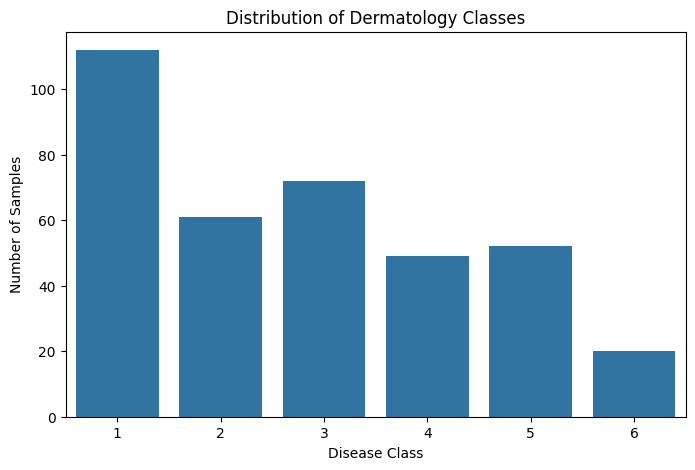

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Distribution of Dermatology Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

In [ ]:
class_counts = df["class"].value_counts().sort_index()

print(class_counts)

class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


In [ ]:
class_percentage = (
    df["class"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print(class_percentage)

class
1    30.601093
2    16.666667
3    19.672131
4    13.387978
5    14.207650
6     5.464481
Name: proportion, dtype: float64


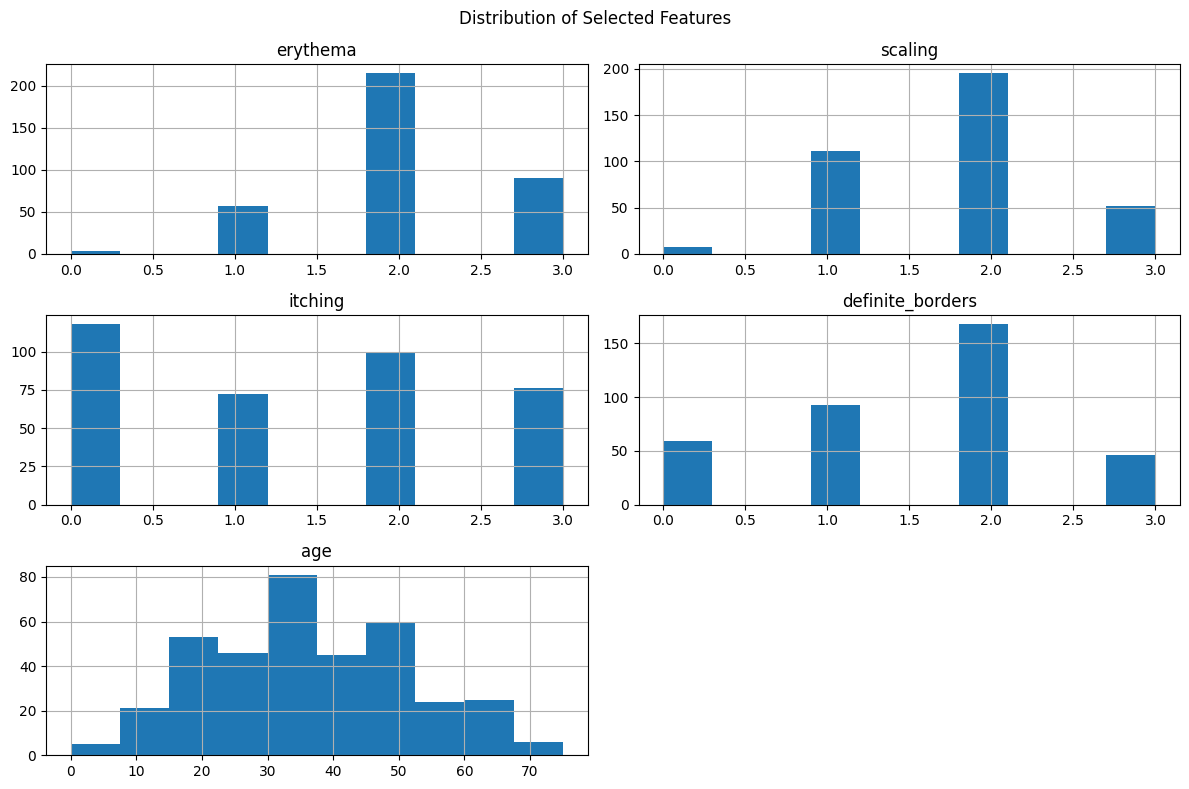

In [ ]:
selected_features = [
    "erythema",
    "scaling",
    "itching",
    "definite_borders",
    "age"
]

df[selected_features].hist(
    figsize=(12, 8),
    bins=10
)

plt.suptitle("Distribution of Selected Features")
plt.tight_layout()
plt.show()

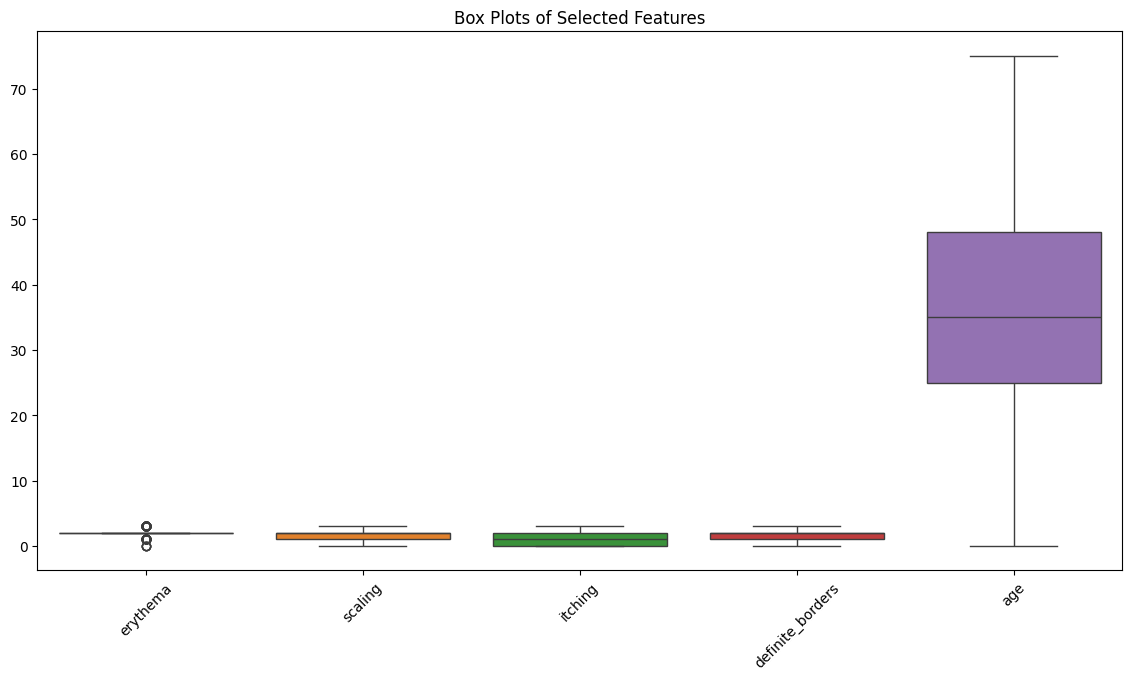

In [ ]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df[selected_features]
)

plt.title("Box Plots of Selected Features")
plt.xticks(rotation=45)
plt.show()

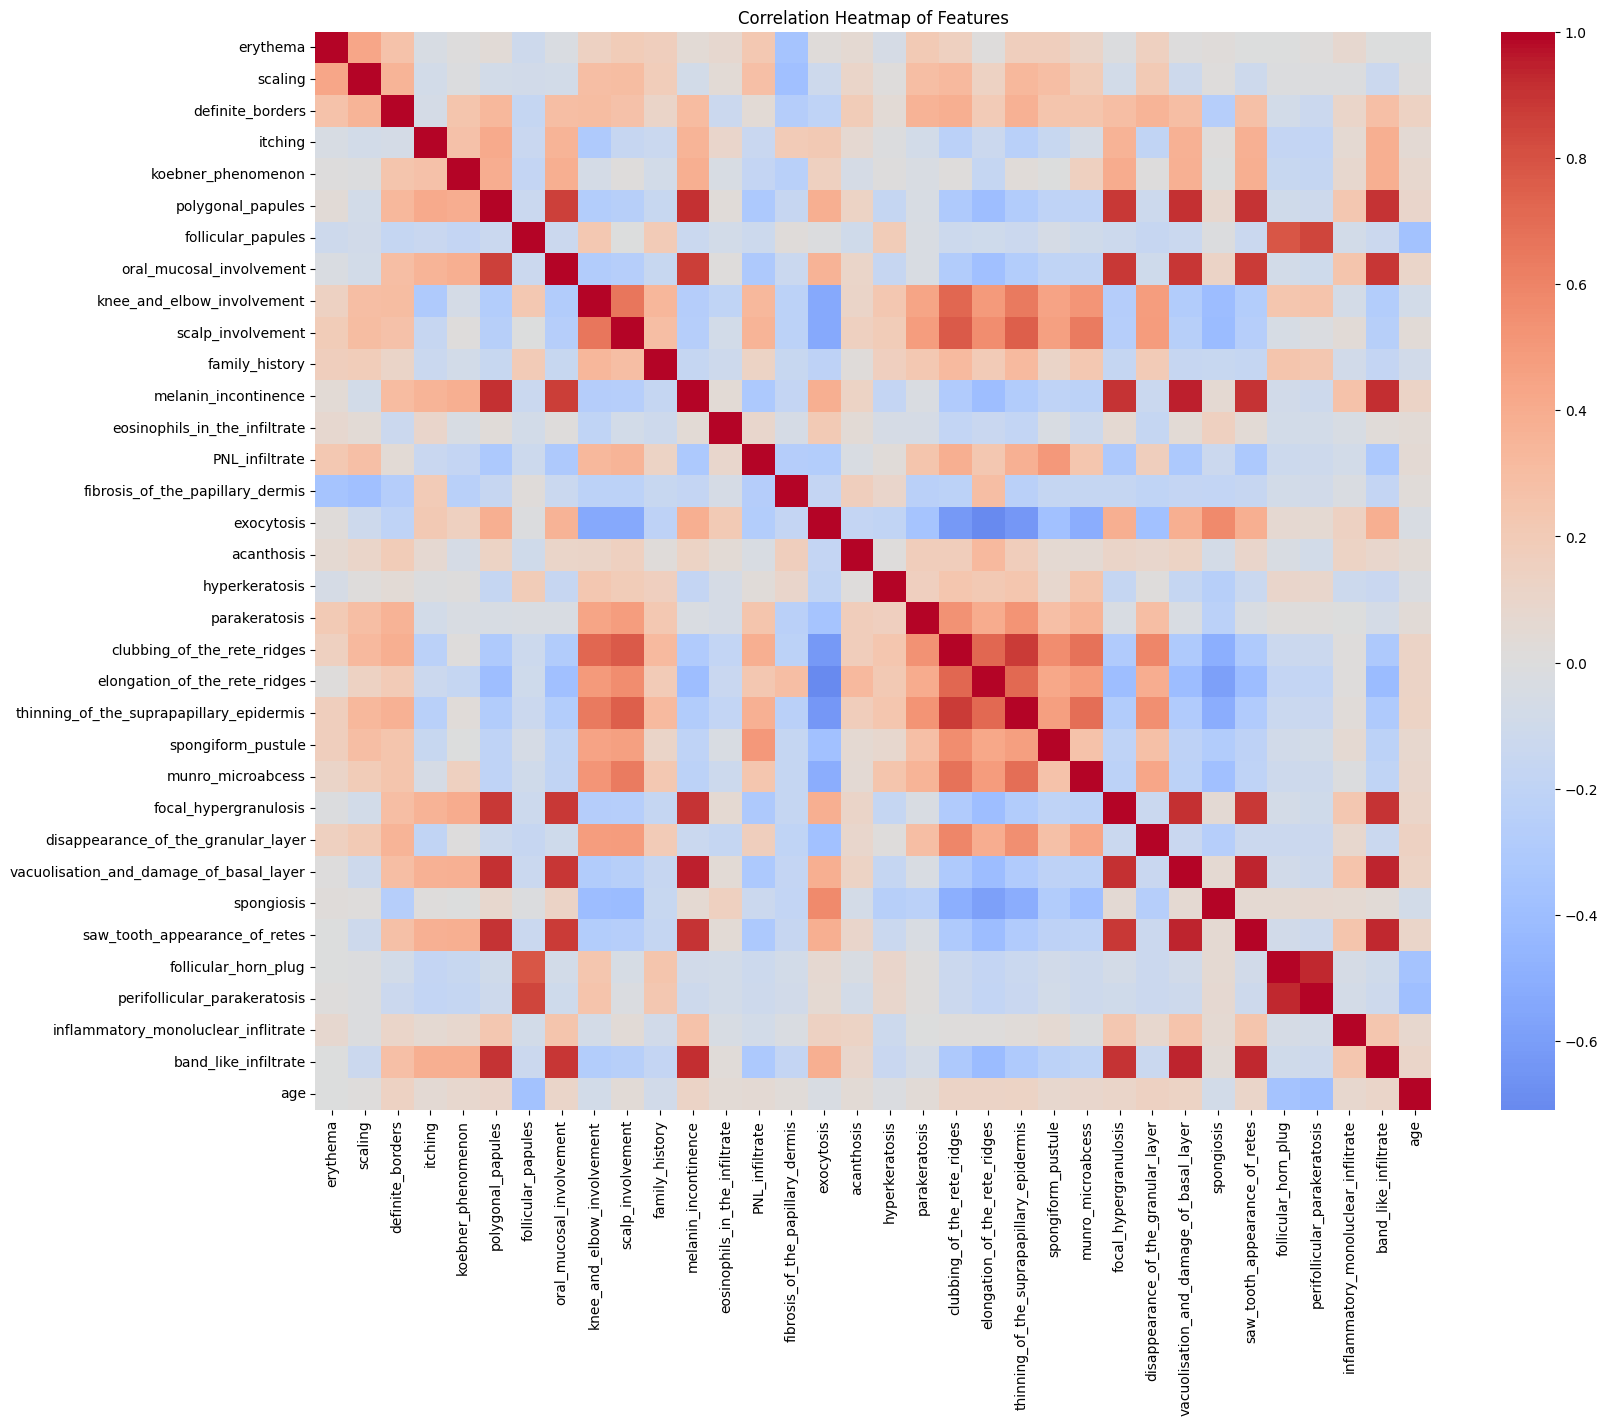

In [ ]:
plt.figure(figsize=(18, 14))

correlation_matrix = df[numeric_columns].corr()

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Features")
plt.show()

In [ ]:
X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (366, 34)
Target shape: (366,)


In [ ]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:", label_encoder.classes_)
print("Encoded classes:", np.unique(y_encoded))

Original classes: [1 2 3 4 5 6]
Encoded classes: [0 1 2 3 4 5]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training samples: 292
Testing samples: 74
Training class distribution:
0    89
1    49
2    57
3    39
4    42
5    16
Name: count, dtype: int64

Testing class distribution:
0    23
1    12
2    15
3    10
4    10
5     4
Name: count, dtype: int64


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
logistic_model = LogisticRegression(
    max_iter=2000,
    multi_class="auto"
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_lr = logistic_model.predict(X_test_scaled)
y_prob_lr = logistic_model.predict_proba(X_test_scaled)

In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

y_pred_knn = knn_model.predict(X_test_scaled)
y_prob_knn = knn_model.predict_proba(X_test_scaled)

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model.fit(
    X_train,
    y_train
)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)

In [ ]:
svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

svm_model.fit(
    X_train_scaled,
    y_train
)

y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)

In [ ]:
def evaluate_model(name, y_test, y_pred):

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted"
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted"
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted"
    )

    return {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Logistic Regression",
        y_test,
        y_pred_lr
    )
)

results.append(
    evaluate_model(
        "KNN",
        y_test,
        y_pred_knn
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
)

results.append(
    evaluate_model(
        "SVM",
        y_test,
        y_pred_svm
    )
)

results_df = pd.DataFrame(results)

display(results_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.959459,0.968815,0.959459,0.960642
1,KNN,0.905405,0.919305,0.905405,0.908094
2,Random Forest,0.959459,0.960688,0.959459,0.959543
3,SVM,0.972973,0.977477,0.972973,0.972973


In [ ]:
print("Logistic Regression")
print(
    classification_report(
        y_test,
        y_pred_lr,
        target_names=[
            "Psoriasis",
            "Seborrheic dermatitis",
            "Lichen planus",
            "Pityriasis rosea",
            "Chronic dermatitis",
            "Pityriasis rubra pilaris"
        ]
    )
)

Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
   Seborrheic dermatitis       1.00      0.83      0.91        12
           Lichen planus       1.00      0.93      0.97        15
        Pityriasis rosea       0.77      1.00      0.87        10
      Chronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.96        74
               macro avg       0.96      0.96      0.96        74
            weighted avg       0.97      0.96      0.96        74



In [ ]:
print("KNN")
print(
    classification_report(
        y_test,
        y_pred_knn,
        target_names=[
            "Psoriasis",
            "Seborrheic dermatitis",
            "Lichen planus",
            "Pityriasis rosea",
            "Chronic dermatitis",
            "Pityriasis rubra pilaris"
        ]
    )
)

KNN
                          precision    recall  f1-score   support

               Psoriasis       1.00      0.96      0.98        23
   Seborrheic dermatitis       0.80      0.67      0.73        12
           Lichen planus       1.00      0.93      0.97        15
        Pityriasis rosea       0.64      0.90      0.75        10
      Chronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.91        74
               macro avg       0.91      0.91      0.90        74
            weighted avg       0.92      0.91      0.91        74



In [ ]:
print("Random Forest")
print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=[
            "Psoriasis",
            "Seborrheic dermatitis",
            "Lichen planus",
            "Pityriasis rosea",
            "Chronic dermatitis",
            "Pityriasis rubra pilaris"
        ]
    )
)

Random Forest
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
   Seborrheic dermatitis       0.91      0.83      0.87        12
           Lichen planus       1.00      1.00      1.00        15
        Pityriasis rosea       0.82      0.90      0.86        10
      Chronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.96        74
               macro avg       0.95      0.96      0.95        74
            weighted avg       0.96      0.96      0.96        74



In [ ]:
print("SVM")
print(
    classification_report(
        y_test,
        y_pred_svm,
        target_names=[
            "Psoriasis",
            "Seborrheic dermatitis",
            "Lichen planus",
            "Pityriasis rosea",
            "Chronic dermatitis",
            "Pityriasis rubra pilaris"
        ]
    )
)

SVM
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
   Seborrheic dermatitis       1.00      0.83      0.91        12
           Lichen planus       1.00      1.00      1.00        15
        Pityriasis rosea       0.83      1.00      0.91        10
      Chronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.97        74
               macro avg       0.97      0.97      0.97        74
            weighted avg       0.98      0.97      0.97        74



In [ ]:
models_predictions = {
    "Logistic Regression": y_pred_lr,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf,
    "SVM": y_pred_svm
}

class_names = [
    "Psoriasis",
    "Seborrheic dermatitis",
    "Lichen planus",
    "Pityriasis rosea",
    "Chronic dermatitis",
    "Pityriasis rubra pilaris"
]

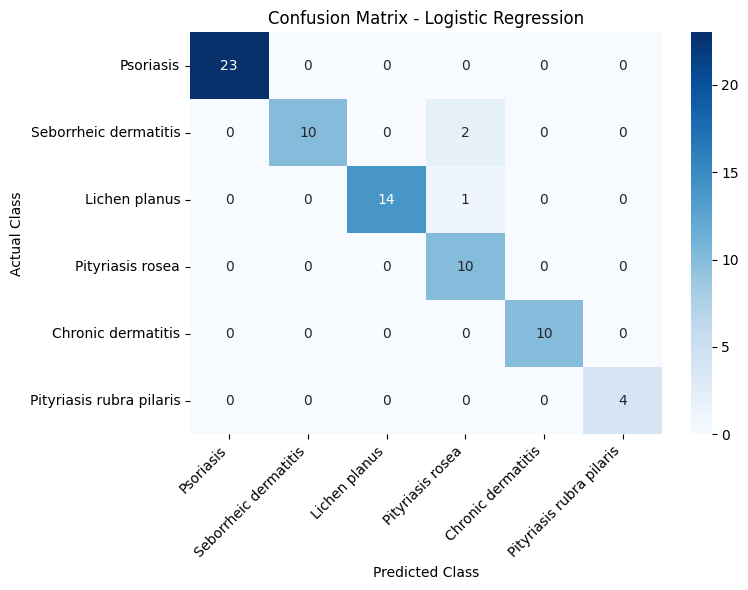

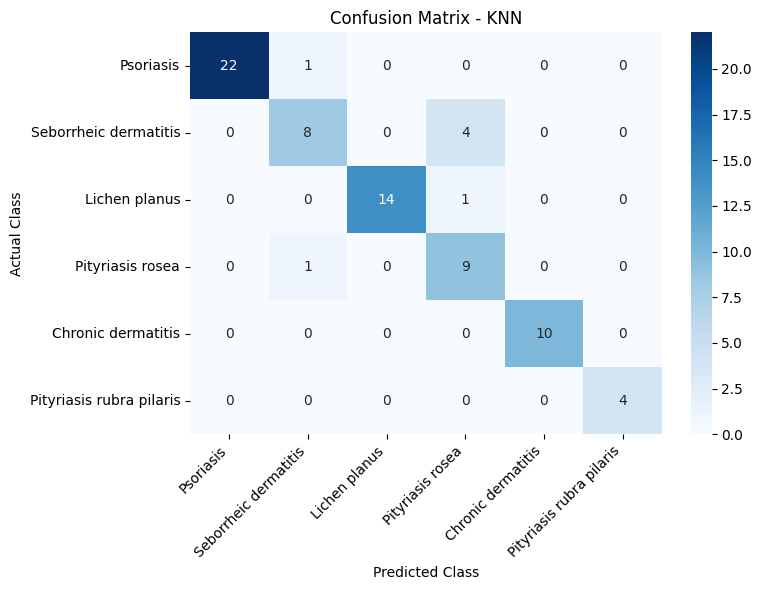

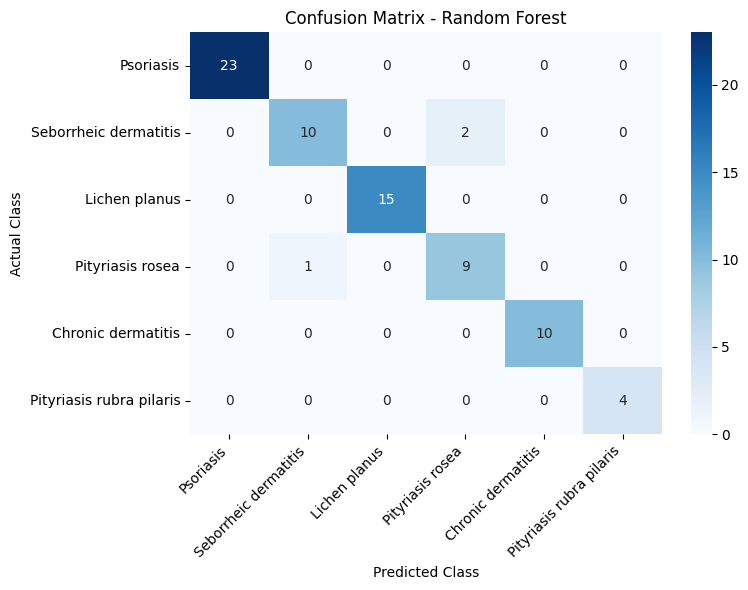

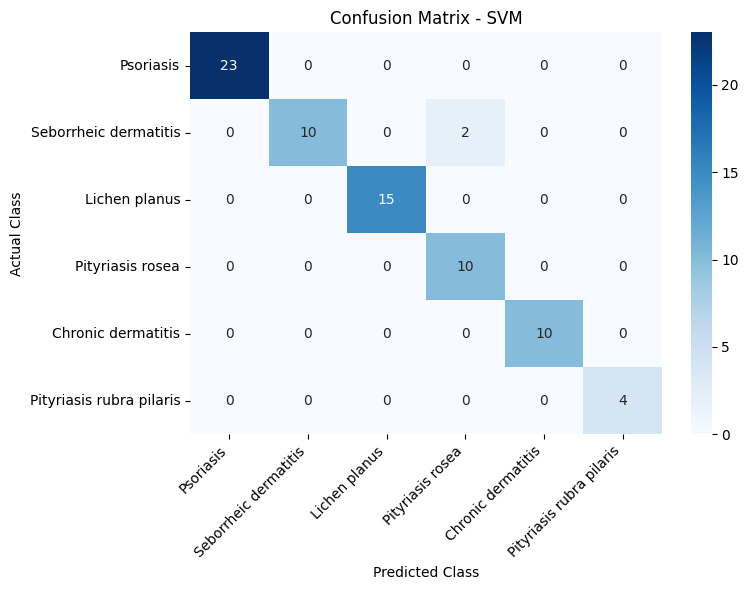

In [ ]:
for model_name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [ ]:
y_test_binary = label_binarize(
    y_test,
    classes=np.arange(6)
)


probabilities = {
    "Logistic Regression": y_prob_lr,
    "KNN": y_prob_knn,
    "Random Forest": y_prob_rf,
    "SVM": y_prob_svm
}

In [ ]:
for model_name, probabilities_model in probabilities.items():

    auc_score = roc_auc_score(
        y_test_binary,
        probabilities_model,
        multi_class="ovr",
        average="weighted"
    )

    print(f"{model_name}: ROC-AUC = {auc_score:.4f}")

Logistic Regression: ROC-AUC = 0.9991
KNN: ROC-AUC = 0.9871
Random Forest: ROC-AUC = 0.9986
SVM: ROC-AUC = 0.9983


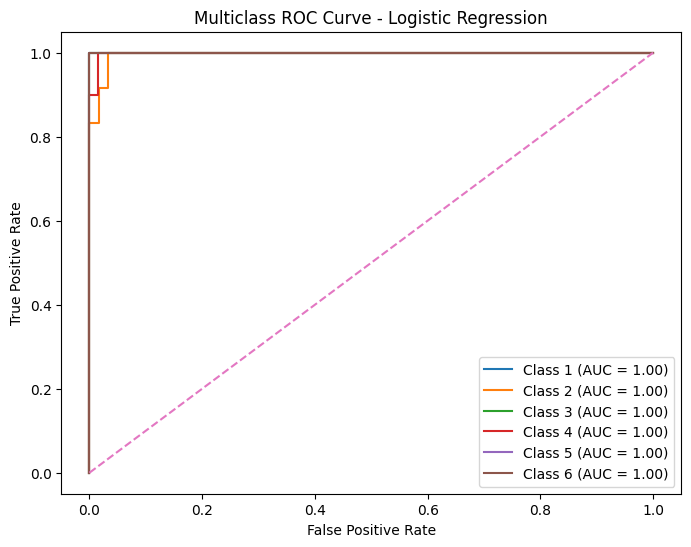

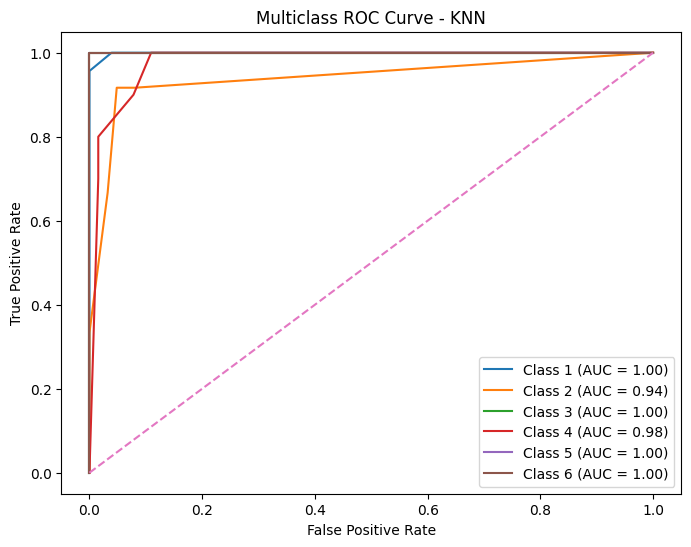

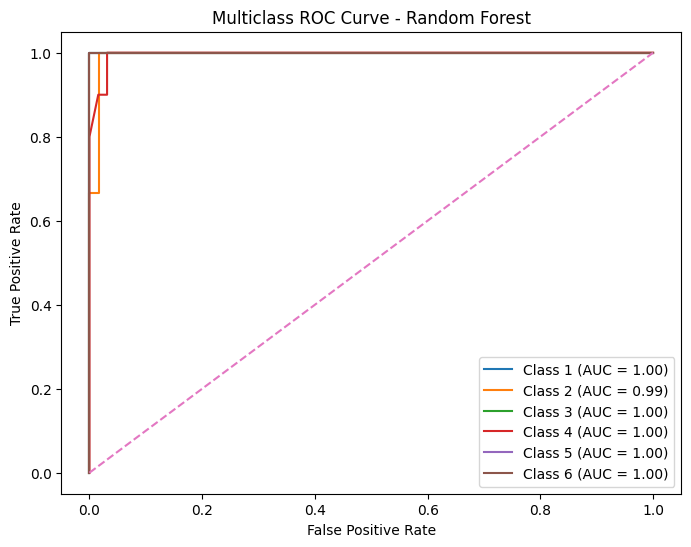

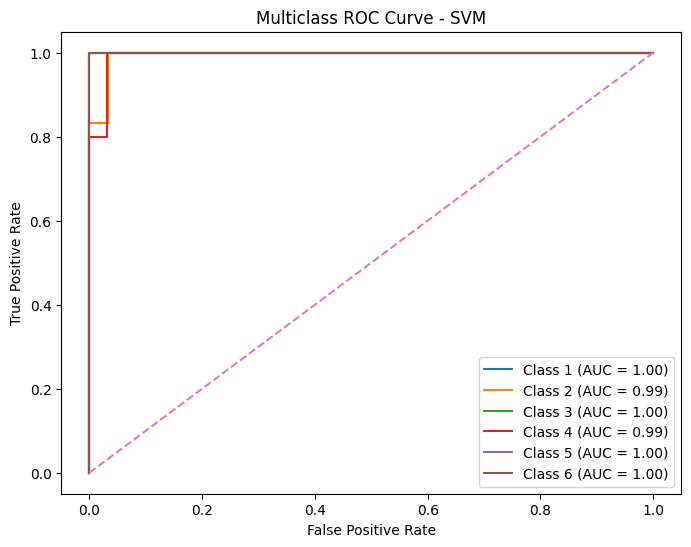

In [ ]:
for model_name, probabilities_model in probabilities.items():

    plt.figure(figsize=(8, 6))

    for i in range(6):

        fpr, tpr, _ = roc_curve(
            y_test_binary[:, i],
            probabilities_model[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"Class {i+1} (AUC = {roc_auc:.2f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Multiclass ROC Curve - {model_name}")
    plt.legend()
    plt.show()

In [ ]:
auc_results = []

for model_name, probabilities_model in probabilities.items():

    auc_score = roc_auc_score(
        y_test_binary,
        probabilities_model,
        multi_class="ovr",
        average="weighted"
    )

    auc_results.append({
        "Model": model_name,
        "ROC-AUC": auc_score
    })

auc_df = pd.DataFrame(auc_results)

final_results = results_df.merge(
    auc_df,
    on="Model"
)

display(final_results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.959459,0.968815,0.959459,0.960642,0.999135
1,KNN,0.905405,0.919305,0.905405,0.908094,0.987076
2,Random Forest,0.959459,0.960688,0.959459,0.959543,0.998600
3,SVM,0.972973,0.977477,0.972973,0.972973,0.998284


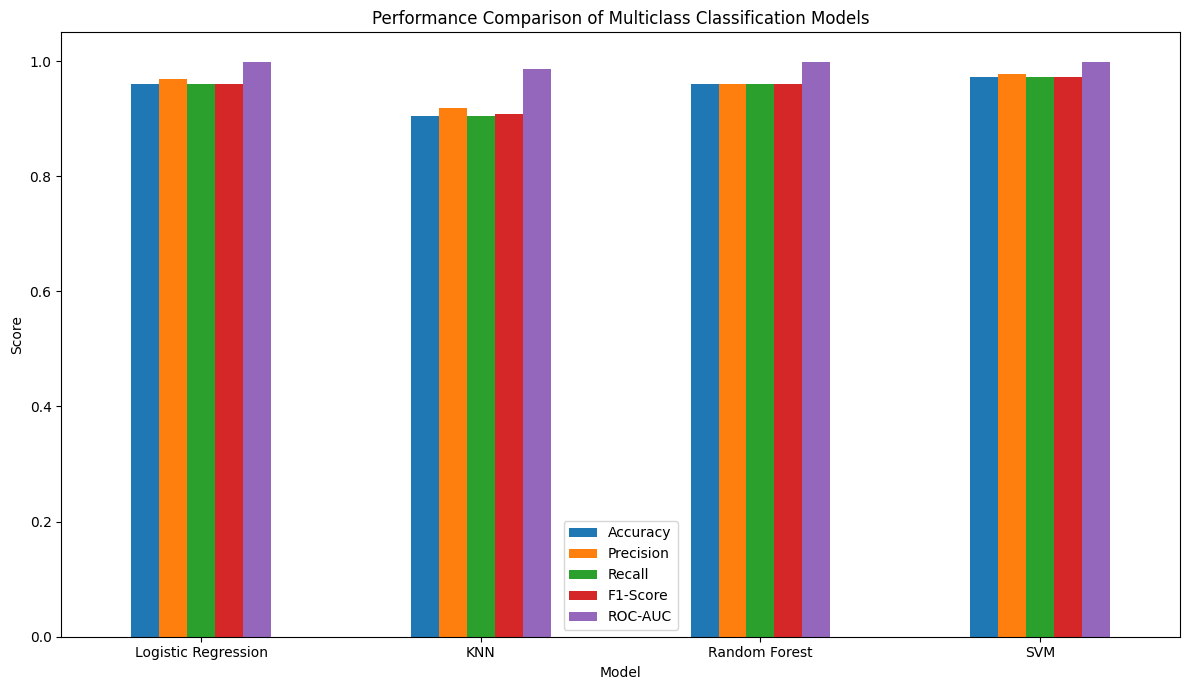

In [ ]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

final_results.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 7)
)

plt.title("Performance Comparison of Multiclass Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(10))

,Feature,Importance
19,clubbing_of_the_rete_ridges,0.103995
14,fibrosis_of_the_papillary_dermis,0.078025
21,thinning_of_the_suprapapillary_epidermis,0.070083
4,koebner_phenomenon,0.061630
27,spongiosis,0.055657
20,elongation_of_the_rete_ridges,0.054517
13,PNL_infiltrate,0.041216
26,vacuolisation_and_damage_of_basal_layer,0.039338
28,saw_tooth_appearance_of_retes,0.038373
32,band_like_infiltrate,0.034791


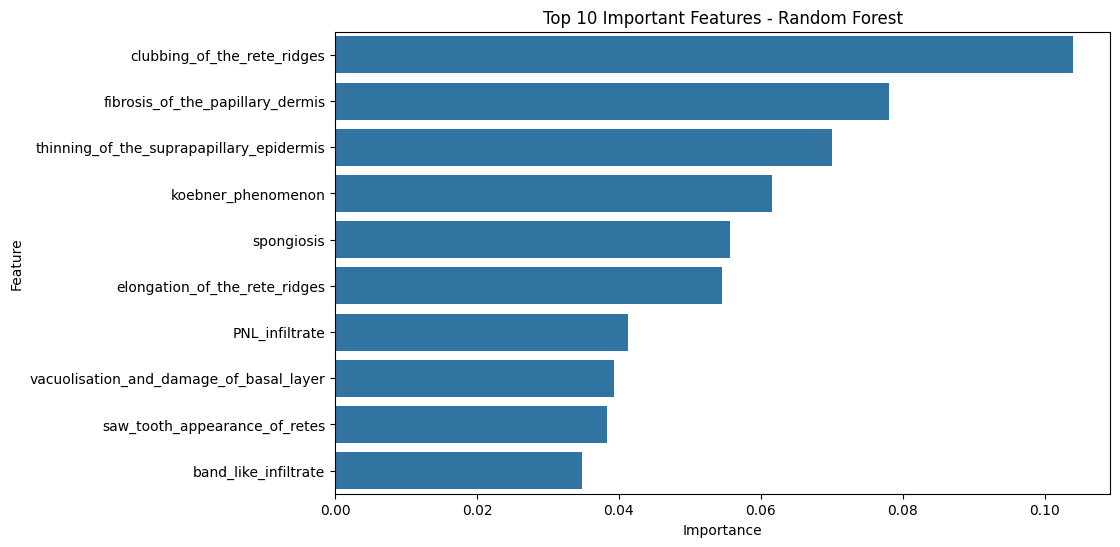

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.show()

In [ ]:
for metric in metrics:
    best_index = final_results[metric].idxmax()

    print(
        f"Highest {metric}: "
        f"{final_results.loc[best_index, 'Model']} "
        f"({final_results.loc[best_index, metric]:.4f})"
    )

Highest Accuracy: SVM (0.9730)
Highest Precision: SVM (0.9775)
Highest Recall: SVM (0.9730)
Highest F1-Score: SVM (0.9730)
Highest ROC-AUC: Logistic Regression (0.9991)
